# NIFTY 50 Direction Prediction
**Harshul Saini & Vishesh Gupta**

**Goal:** predict whether tomorrow's NIFTY 50 close will be **higher (UP = 1)** or **lower/equal (DOWN = 0)** than today's close.

**How this notebook is organised** (each section = one required component):

| Section | Component |
|---|---|
| 0 | Data download |
| 1 | Exploratory Data Analysis (EDA) |
| 2 | Feature Derivation |
| 3 | Classification |
| 4 | Regularization |
| 5 | Hyperparameter Tuning |
| 6 | Ensemble Techniques |
| 7 | Performance Analysis |
| 8 | Real-life use: walk-forward retraining + tomorrow's signal |
| 9 | Conclusion |

**The real-life rule we follow everywhere:** the prediction is made at **3:30 PM IST (market close) on day t**, so every feature must use only information that is known at that moment. Nothing from the future is allowed.

In [1]:
# ===== SETUP: libraries and settings =====
import os
import warnings
warnings.filterwarnings("ignore")   # hide library version warnings to keep output clean

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.stats import norm

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score, KFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap

SEED = 42                 # fixed random seed so results are repeatable
START_DATE = "2015-01-01"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.float_format", "{:.4f}".format)

## 0. Data

We download daily data from **Yahoo Finance** with `yfinance`. Besides NIFTY 50 itself we also take a few related markets, because the Indian market reacts strongly to them:

| Name | Ticker | Why we use it | Known at 3:30 PM IST on day t? |
|---|---|---|---|
| NIFTY 50 | `^NSEI` | the index we predict | yes (same day) |
| India VIX | `^INDIAVIX` | "fear index": expected volatility | yes (same day) |
| Bank Nifty | `^NSEBANK` | banks are about one-third of NIFTY | yes (same day) |
| S&P 500, Nasdaq | `^GSPC`, `^IXIC` | US markets move the whole world | only **yesterday's** close (US closes at night in India) |
| USD/INR | `INR=X` | foreign money flows into/out of India | only yesterday's value |
| Crude oil | `CL=F` | India imports most of its oil | only yesterday's value |

In [2]:
# ===== STEP 0: DOWNLOAD DATA =====
# The first run downloads and saves CSV files in data/. Later runs read those
# files, so the results stay the same. Delete data/ to get the latest data.
TICKERS = {
    "nifty":     "^NSEI",
    "vix":       "^INDIAVIX",
    "banknifty": "^NSEBANK",
    "sp500":     "^GSPC",
    "nasdaq":    "^IXIC",
    "usdinr":    "INR=X",
    "crude":     "CL=F",
}

raw = {}
for name, ticker in TICKERS.items():
    path = f"{DATA_DIR}/{name}.csv"
    if not os.path.exists(path):
        d = yf.download(ticker, start=START_DATE, auto_adjust=True, progress=False)
        d.columns = d.columns.get_level_values(0)   # flatten yfinance's two-level column names
        d.to_csv(path)
    raw[name] = pd.read_csv(path, index_col=0, parse_dates=True)

nifty = raw["nifty"][["Open", "High", "Low", "Close", "Volume"]].copy()
print("NIFTY rows:", len(nifty), "| from", nifty.index.min().date(), "to", nifty.index.max().date())
nifty.tail()

NIFTY rows: 2912 | from 2015-01-02 to 2026-10-30


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-26,22524.4004,22753.1992,22387.3496,22753.1992,310200
2026-10-27,22708.8008,22829.7500,22636.8496,22749.7500,400900
2026-10-28,22678.0000,22778.0508,22497.6992,22698.8496,295000
2026-10-29,22690.6504,22961.9492,22656.7500,22936.7500,344000
2026-10-30,22964.5000,23118.0996,22905.0996,23053.0996,328600


## 1. Exploratory Data Analysis (EDA)

Before building any model we look at the data to find **patterns, trends, distributions and problems**. Questions we want answered:
1. Is the data clean (missing values, duplicate dates, bad values)?
2. How does price behave over time, and is it stationary?
3. How are daily returns distributed?
4. Are UP and DOWN days balanced?
5. Does yesterday's move tell us anything about today's move?

In [3]:
# ===== STEP 1: EXPLORATORY DATA ANALYSIS (EDA) =====
# 1a. Basic data quality checks
print("Missing values per column:\n", nifty.isna().sum().to_dict())
print("Duplicate dates          :", nifty.index.duplicated().sum())
print("Days with zero volume    :", (nifty["Volume"] == 0).sum())
print("Days where High == Low   :", (nifty["High"] == nifty["Low"]).sum())
nifty.describe()

Missing values per column:
 {'Open': 0, 'High': 0, 'Low': 0, 'Close': 0, 'Volume': 0}
Duplicate dates          : 0
Days with zero volume    : 28
Days where High == Low   : 0


,Open,High,Low,Close,Volume
count,2912.0000,2912.0000,2912.0000,2912.0000,2912.0000
mean,15203.3301,15272.3136,15112.9105,15194.1780,326091.8269
std,6039.1124,6062.1511,6015.7170,6039.6292,184975.6130
min,7023.6499,7034.2002,6825.7998,6970.6001,0.0000
25%,10053.5750,10102.5376,9985.5371,10029.7749,205375.0000
50%,13383.7500,13463.7500,13217.4253,13374.3501,274450.0000
75%,19860.6753,19995.9248,19816.3374,19920.8379,391600.0000
max,26333.6992,26373.1992,26210.0508,26328.5508,1811000.0000


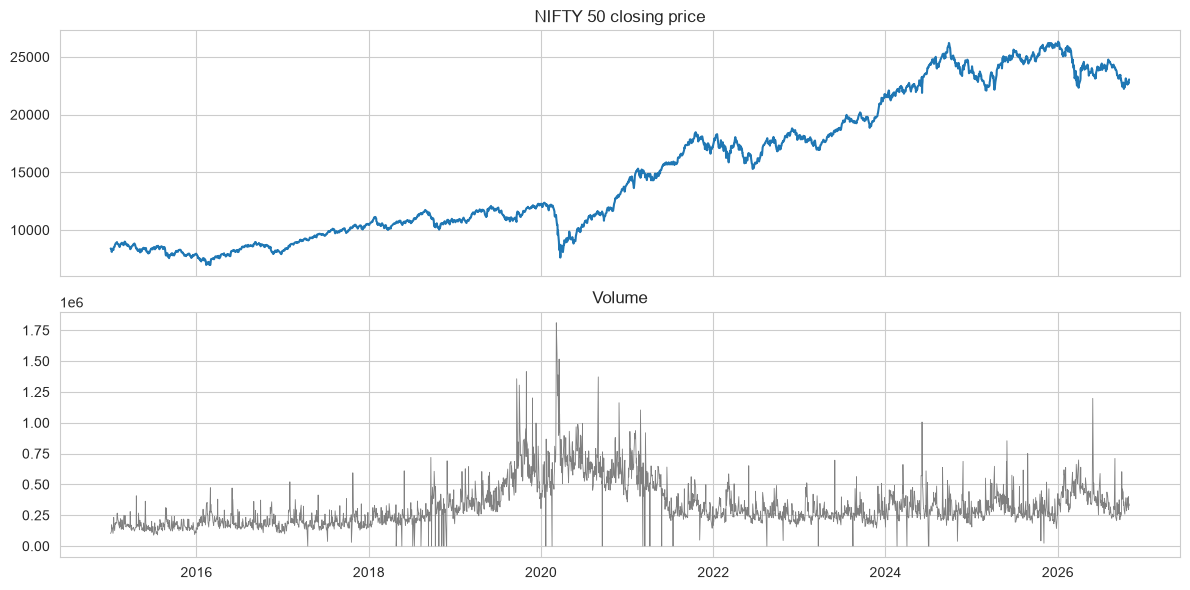

In [4]:
# 1b. Price and volume over time
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(nifty["Close"])
ax[0].set_title("NIFTY 50 closing price")
ax[1].plot(nifty["Volume"], color="gray", linewidth=0.6)
ax[1].set_title("Volume")
plt.tight_layout()
plt.show()

Mean daily return : 0.040%
Std of daily return: 1.017%
Skewness          : -1.00  (normal = 0)
Excess kurtosis   : 16.99  (normal = 0, higher = more extreme days)

Five biggest one-day falls (%):
Date
2020-03-23   -12.9800
2020-03-12    -8.3000
2020-03-16    -7.6100
2024-06-04    -5.9300
2015-08-24    -5.9200


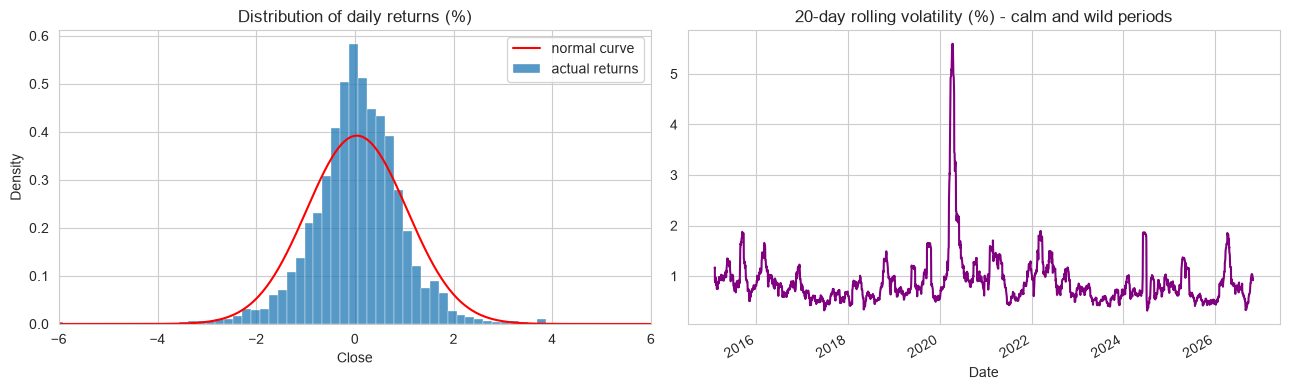

In [5]:
# 1c. Daily returns: how are they spread?
ret = nifty["Close"].pct_change().dropna() * 100     # daily % change

print(f"Mean daily return : {ret.mean():.3f}%")
print(f"Std of daily return: {ret.std():.3f}%")
print(f"Skewness          : {ret.skew():.2f}  (normal = 0)")
print(f"Excess kurtosis   : {ret.kurt():.2f}  (normal = 0, higher = more extreme days)")
print("\nFive biggest one-day falls (%):")
print(ret.nsmallest(5).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ret, bins=120, stat="density", ax=ax[0], label="actual returns")
x = np.linspace(-6, 6, 300)
ax[0].plot(x, norm.pdf(x, ret.mean(), ret.std()), "r", label="normal curve")
ax[0].set_xlim(-6, 6)
ax[0].set_title("Distribution of daily returns (%)")
ax[0].legend()

ret.rolling(20).std().plot(ax=ax[1], color="purple")
ax[1].set_title("20-day rolling volatility (%) - calm and wild periods")
plt.tight_layout()
plt.show()

Share of UP days  : 0.533
Share of DOWN days: 0.467


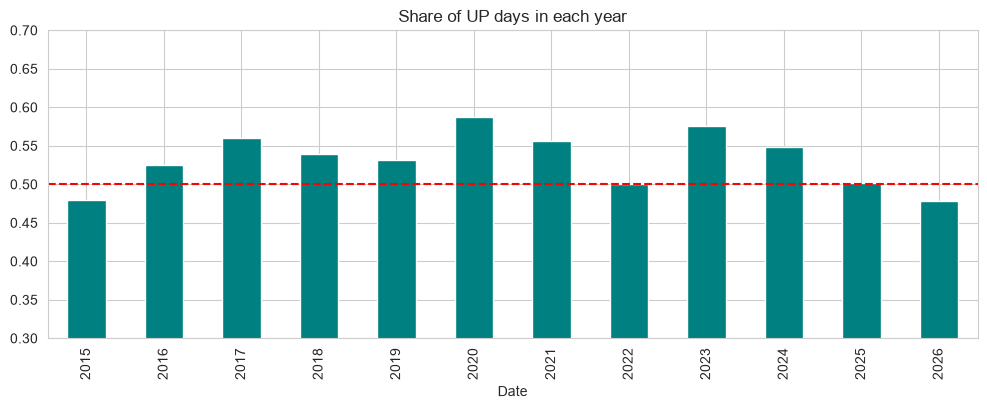

In [6]:
# 1d. Target balance: how many UP vs DOWN days?
up_day = (nifty["Close"].shift(-1) > nifty["Close"]).iloc[:-1].astype(int)
print("Share of UP days  :", round(up_day.mean(), 3))
print("Share of DOWN days:", round(1 - up_day.mean(), 3))

up_day.groupby(up_day.index.year).mean().plot(kind="bar", color="teal")
plt.axhline(0.5, color="red", linestyle="--")
plt.title("Share of UP days in each year")
plt.ylim(0.3, 0.7)
plt.show()

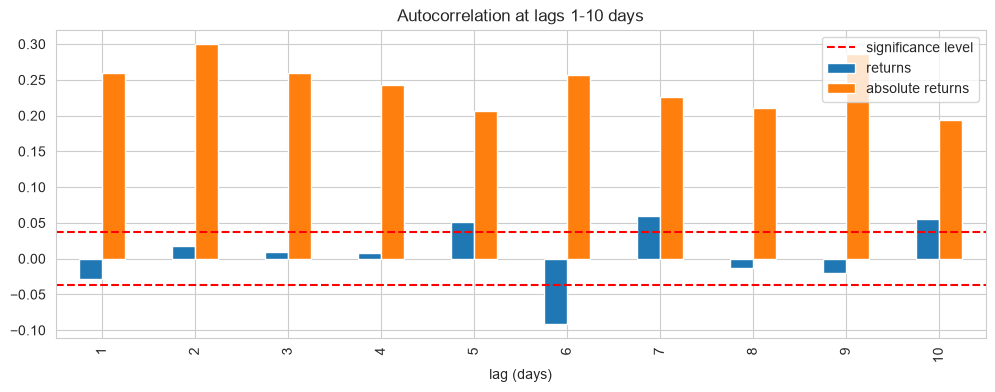

In [7]:
# 1e. Does yesterday's move predict today's? (autocorrelation)
lags = range(1, 11)
ac_ret = [ret.autocorr(lag) for lag in lags]          # returns
ac_abs = [ret.abs().autocorr(lag) for lag in lags]    # size of the move (volatility)

pd.DataFrame({"returns": ac_ret, "absolute returns": ac_abs}, index=lags).plot(kind="bar")
plt.axhline(2 / np.sqrt(len(ret)), color="red", linestyle="--", label="significance level")
plt.axhline(-2 / np.sqrt(len(ret)), color="red", linestyle="--")
plt.title("Autocorrelation at lags 1-10 days")
plt.xlabel("lag (days)")
plt.legend()
plt.show()

### EDA findings
1. **Data quality:** 2,912 trading days (Jan 2015 - Oct 2026), no missing values and no duplicate dates. But **28 days have volume = 0**, which is impossible for NIFTY, so these are data errors (fixed in Section 2). Volume also changes level over time (much higher in 2019-2021), so we use volume *relative to its recent average*, not raw volume.
2. **Trend / stationarity:** price rose from ~7,000 to ~26,000, with the COVID crash in March 2020 and a fall since late 2025. The price series is **not stationary** (its average keeps changing), so raw prices cannot be used as features. We use returns and ratios instead.
3. **Distribution:** average daily return is only +0.04% with a standard deviation of 1.02%. Skewness of -1.0 and excess kurtosis of ~17 mean **fat tails**: extreme days (like -13% on 23 March 2020) happen far more often than a normal curve predicts, and big falls are bigger than big rises. Because of these outliers we prefer robust tree models and clip broken values (crude oil).
4. **Volatility clustering:** the absolute size of moves is clearly autocorrelated (0.2-0.3 at every lag): wild days follow wild days, calm follows calm. So **volatility is predictable**, and volatility features are worth adding.
5. **Direction is close to random:** the autocorrelation of returns themselves is almost zero (mostly within the significance band). Yesterday's direction tells us very little about today's. We should therefore expect accuracy **only slightly above 50%**.
6. **Class balance:** 53.3% UP vs 46.7% DOWN, mildly imbalanced. We use ROC-AUC and compare against an "always UP" baseline. The UP share also **changes by year** (58.6% in 2020, 47.8% in 2026), so the market's behaviour shifts over time. Our test period (late 2024 onwards) has fewer UP days than the training period.

## 2. Feature Derivation

Raw prices are bad model inputs: NIFTY was ~8,000 in 2015 and ~25,000 later, so a model trained on old prices sees "new" numbers in the test period. We therefore turn prices into **scale-free signals** (returns, ratios, percentages) that mean the same thing in every year.

| Group | Features | Why it can help |
|---|---|---|
| Returns | `ret_1`, `ret_5`, `ret_10` | recent price change; comparable across years |
| Lags | `ret_lag_1..4` | does the move of the last few days carry over? |
| Trend | `close_vs_sma10/20/50/200` | price above its average = uptrend, below = downtrend |
| Momentum | `rsi_14`, `macd_hist`, `stoch_k` | is the market overbought/oversold, is momentum speeding up or fading? |
| Volatility | `bb_width`, `atr_pct`, `volatility_20` | calm and wild periods behave differently (EDA 1c, 1e) |
| Candle | `gap`, `intraday_ret`, `close_position` | did buyers or sellers control the day? closing near the high = strength |
| Volume | `volume_ratio`, `obv_10` | is a move backed by heavy trading? |
| Long-term | `dist_52w_high` | how far are we from the yearly high? |
| Calendar | `day_of_week` | some weekdays may behave differently |
| India | `vix`, `vix_change`, `banknifty_ret` | fear level and the biggest NIFTY sector |
| Global | `sp500_ret`, `nasdaq_ret`, `usdinr_ret`, `crude_ret` | world markets, currency and oil (yesterday's values only) |

**No look-ahead:** every feature on day t uses data up to day t only (rolling windows look backwards).

In [8]:
# ===== STEP 2: FEATURE DERIVATION =====
# 2a. Cleaning (issues found in EDA)
df = nifty.copy()
df = df[~df.index.duplicated()]                          # remove duplicate dates, if any
df["Volume"] = df["Volume"].replace(0, np.nan).ffill()   # zero volume = missing data -> use previous day

close, high, low, open_ = df["Close"], df["High"], df["Low"], df["Open"]
ret1 = close.pct_change()

In [9]:
# 2b. NIFTY technical features

# Returns and lags
df["ret_1"] = ret1
df["ret_5"] = close.pct_change(5)
df["ret_10"] = close.pct_change(10)
for k in range(1, 5):
    df[f"ret_lag_{k}"] = ret1.shift(k)

# Trend: how far the price is from its moving average (0.02 = 2% above)
for n in [10, 20, 50, 200]:
    df[f"close_vs_sma{n}"] = close / close.rolling(n).mean() - 1

# Momentum: RSI (14 days). Above 70 = overbought, below 30 = oversold
change = close.diff()
avg_gain = change.clip(lower=0).rolling(14).mean()
avg_loss = (-change.clip(upper=0)).rolling(14).mean()
df["rsi_14"] = 100 - 100 / (1 + avg_gain / avg_loss)

# Momentum: MACD histogram, divided by price so it is comparable across years
macd = close.ewm(span=12).mean() - close.ewm(span=26).mean()
df["macd_hist"] = (macd - macd.ewm(span=9).mean()) / close

# Momentum: Stochastic %K = where today's close is inside the 14-day high-low range
low14, high14 = low.rolling(14).min(), high.rolling(14).max()
df["stoch_k"] = (close - low14) / (high14 - low14) * 100

# Volatility
df["bb_width"] = 4 * close.rolling(20).std() / close.rolling(20).mean()   # Bollinger band width
true_range = pd.concat([high - low, (high - close.shift()).abs(), (low - close.shift()).abs()], axis=1).max(axis=1)
df["atr_pct"] = true_range.rolling(14).mean() / close                      # ATR as % of price
df["volatility_20"] = ret1.rolling(20).std()

# Candle / gap
df["gap"] = open_ / close.shift(1) - 1                    # opening jump vs yesterday's close
df["intraday_ret"] = close / open_ - 1                     # move from open to close
df["close_position"] = (close - low) / (high - low)        # 1 = closed at day's high, 0 = at day's low

# Volume
df["volume_ratio"] = df["Volume"] / df["Volume"].rolling(20).mean()          # today's volume vs normal
signed_volume = np.sign(ret1) * df["Volume"]                                    # OBV idea: + on up days, - on down days
df["obv_10"] = signed_volume.rolling(10).sum() / df["Volume"].rolling(10).sum() # -1 (all selling) .. +1 (all buying)

# Long-term position and calendar
df["dist_52w_high"] = close / close.rolling(252).max() - 1
df["day_of_week"] = df.index.dayofweek                     # 0 = Monday ... 4 = Friday

In [10]:
# 2c. Other markets, aligned so we only use what was known at 3:30 PM IST
# Indian markets (VIX, Bank Nifty) close at the same time as NIFTY -> delay 0 days.
# Foreign markets close after Indian market hours -> on day t we only know
# their previous close. We push their dates forward by 1 day and then take the
# latest available value on every NIFTY trading day.
def aligned_close(name, delay_days):
    s = raw[name]["Close"].copy()
    s.index = s.index + pd.Timedelta(days=delay_days)
    return s.reindex(df.index, method="ffill")

vix = aligned_close("vix", 0)
df["vix"] = vix
df["vix_change"] = vix.pct_change()
df["banknifty_ret"] = aligned_close("banknifty", 0).pct_change()
for name in ["sp500", "nasdaq", "usdinr", "crude"]:
    df[f"{name}_ret"] = aligned_close(name, 1).pct_change()

# Crude oil futures went NEGATIVE in April 2020, which gives absurd % changes.
# Clip to +-20% so one broken value cannot dominate the model.
df["crude_ret"] = df["crude_ret"].clip(-0.2, 0.2)

In [11]:
# 2d. Target: 1 if tomorrow's close is higher than today's, else 0
df["next_ret"] = close.shift(-1) / close - 1      # used only for the target and the backtest, NEVER as a feature
df["target"] = (df["next_ret"] > 0).astype(int)

FEATURES = [c for c in df.columns if c not in ["Open", "High", "Low", "Close", "Volume", "next_ret", "target"]]
df = df.replace([np.inf, -np.inf], np.nan)

# The last day has no "tomorrow" yet -> keep it aside for the live prediction in Section 8
latest_day = df.iloc[[-1]]
data = df.iloc[:-1].dropna()          # drop first ~200 days (rolling windows need history)

print("Number of features:", len(FEATURES))
print("Usable rows       :", len(data), "| from", data.index.min().date(), "to", data.index.max().date())

Number of features: 31
Usable rows       : 2660 | from 2016-01-13 to 2026-10-29


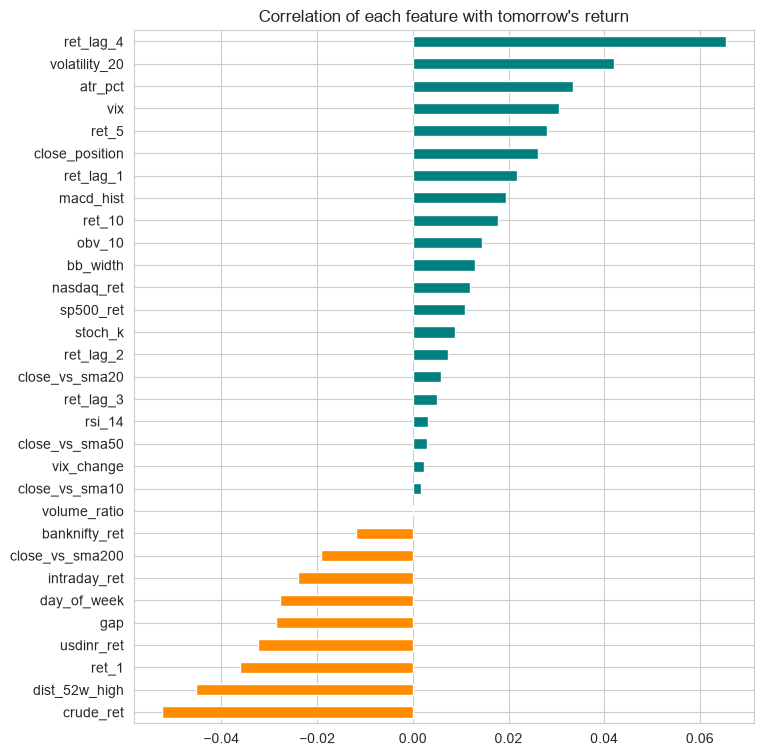

In [12]:
# 2e. How strongly is each feature linked to TOMORROW's return?
link = data[FEATURES].corrwith(data["next_ret"]).sort_values()
link.plot(kind="barh", figsize=(8, 9), color=np.where(link > 0, "teal", "darkorange"))
plt.title("Correlation of each feature with tomorrow's return")
plt.show()

In [13]:
# 2f. Split by TIME: first 80% of days = training, last 20% = testing (no shuffling!)
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]
print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("Test :", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")
print(f"UP share -> train: {train['target'].mean():.3f} | test: {test['target'].mean():.3f}")

# 2g. Remove features that are almost copies of another feature (|correlation| > 0.9).
# Measured on TRAINING data only, so the test set does not influence any decision.
corr = train[FEATURES].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
FEATURES = [f for f in FEATURES if f not in to_drop]
print("\nDropped (repeated information):", to_drop)
print("Final feature count:", len(FEATURES))

X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]

Train: 2016-01-13 to 2024-09-04 (2128 days)
Test : 2024-09-05 to 2026-10-29 (532 days)
UP share -> train: 0.552 | test: 0.483

Dropped (repeated information): ['close_vs_sma10', 'close_vs_sma20', 'volatility_20', 'vix', 'nasdaq_ret']
Final feature count: 26


### Feature findings
- We derived **31 features**. Five were almost copies of another feature (|correlation| > 0.9 on training data) and were removed:
  `close_vs_sma10` ≈ `ret_5`, `close_vs_sma20` ≈ `ret_10`, `volatility_20` ≈ `atr_pct`, `vix` ≈ `atr_pct`, `nasdaq_ret` ≈ `sp500_ret`. **26 features remain.** Removing duplicates makes linear models more stable and the feature importance easier to read.
- Every single feature has a correlation **below 0.07** with tomorrow's return. Each signal on its own is very weak. This is normal for financial data, and it tells us two things: we need models that **combine many weak signals**, and we need **strong regularization** so that the model does not mistake noise for signal.
- Train period: Jan 2016 - Sep 2024 (2,128 days). Test period: Sep 2024 - Oct 2026 (532 days). The first ~250 days of 2015 were used only to warm up the rolling windows (200-day average, 52-week high).

## 3. Classification

Our problem is **binary classification**: each day gets label 1 (UP) or 0 (DOWN).

### Logistic Regression: how it works
1. It computes a weighted sum of the features: $z = w_1x_1 + w_2x_2 + \dots + b$
2. It squeezes $z$ into a probability with the **sigmoid** function: $P(\text{UP}) = \frac{1}{1+e^{-z}}$
3. If $P(\text{UP}) > 0.5$ we predict UP, otherwise DOWN.
4. The weights $w$ are learned by minimising **log-loss**, which punishes confident wrong answers heavily.

### Why we start with it
- It is the standard **baseline** for binary classification: simple, fast and hard to overfit.
- It gives a **probability**, not just a label. That lets us act only on confident days (Section 7).
- Its weights are **interpretable**: we can see which features push towards UP or DOWN.
- Market signals are weak and noisy, and simple linear models often do as well as complex ones in this setting.

Features must be **scaled** (StandardScaler: mean 0, std 1) first, otherwise features with big numbers (like RSI, 0-100) would dominate features with small numbers (like returns, ~0.01).

### Baselines
A model is only useful if it beats trivial rules, so we compare against:
- **Always UP**: the market goes up slightly more often than down.
- **Same as today**: predict that tomorrow repeats today's direction.

In [14]:
# ===== STEP 3: CLASSIFICATION =====
# 3a. Baselines: any real model must beat these
print("Always UP    accuracy:", round(accuracy_score(y_test, np.ones(len(y_test))), 4))
print("Same as today accuracy:", round(accuracy_score(y_test, (test["ret_1"] > 0).astype(int)), 4))

Always UP    accuracy: 0.4831
Same as today accuracy: 0.5244


Train accuracy: 0.563
Test  accuracy: 0.4793
Test  ROC-AUC : 0.4819


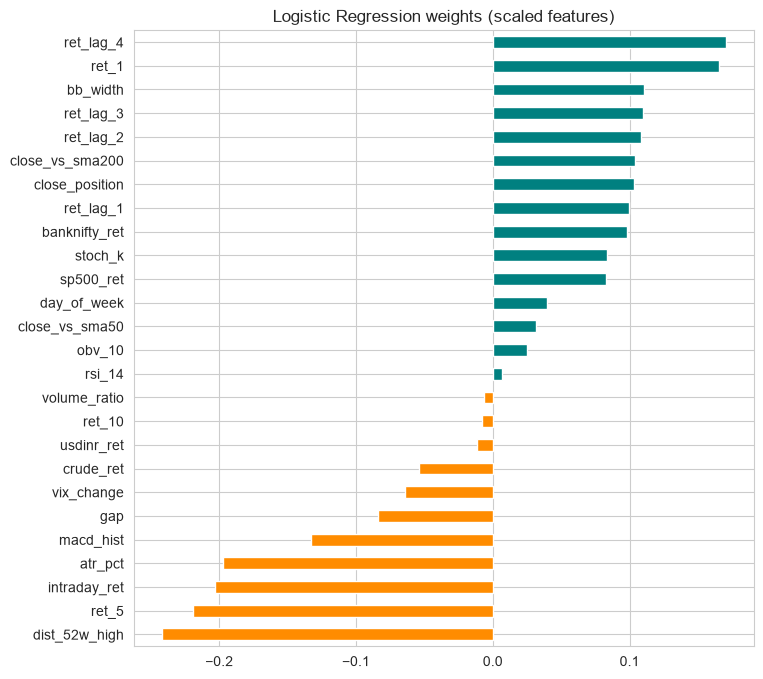

In [15]:
# 3b. Logistic Regression (default settings) inside a pipeline with scaling
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_reg.fit(X_train, y_train)

print("Train accuracy:", round(accuracy_score(y_train, log_reg.predict(X_train)), 4))
print("Test  accuracy:", round(accuracy_score(y_test, log_reg.predict(X_test)), 4))
print("Test  ROC-AUC :", round(roc_auc_score(y_test, log_reg.predict_proba(X_test)[:, 1]), 4))

# Weights: positive = pushes towards UP, negative = pushes towards DOWN
weights = pd.Series(log_reg[-1].coef_[0], index=FEATURES).sort_values()
weights.plot(kind="barh", figsize=(8, 8), color=np.where(weights > 0, "teal", "darkorange"))
plt.title("Logistic Regression weights (scaled features)")
plt.show()

### Classification findings
- **Baselines on the test set:** "always UP" = 48.3% (the test period had more DOWN days than UP days), "same as today" = 52.4%.
- **Logistic Regression with default settings:** 56.3% on training data but only **47.9% on test** (AUC 0.48), i.e. worse than a coin flip. Even a simple linear model **overfits**: it learned patterns from 2016-2024 that did not repeat in 2024-2026.
- **Weights:** the biggest ones are `dist_52w_high` (negative: the further below its yearly high, the more likely an UP day, a "buy the dip" effect), `ret_5` (negative: short-term reversal) and `ret_1`, `ret_lag_4` (positive: short-term momentum). These make financial sense but are too weak and unstable on their own.
- **Conclusion:** the model needs **regularization** (Section 4) and **tuning** (Section 5).

## 4. Regularization

**Overfitting** = the model memorises noise in the training data and then fails on new data. Stock data is mostly noise with a tiny bit of signal, so overfitting is the **biggest danger** in this project.

**Regularization** adds a penalty for complexity, so the model only uses a feature if it really helps.

### For Logistic Regression
Loss = log-loss + penalty on the weights. `C` = 1 / (penalty strength), so **small C = strong regularization**.
- **L2 (Ridge)**: penalty = $\sum w^2$. Shrinks all weights towards 0 but keeps every feature. Good when many features each carry a little information.
- **L1 (Lasso)**: penalty = $\sum |w|$. Pushes useless weights to **exactly 0**, so it also does **feature selection**.

(In scikit-learn 1.9 this is chosen with `l1_ratio`: 1 = L1, 0 = L2.)

### For tree boosting (LightGBM)
Trees overfit by growing too deep and fitting tiny groups of days. We control this with:
- `max_depth` / `num_leaves`: limit tree size
- `min_child_samples`: every leaf must contain at least this many days
- `subsample`, `colsample_bytree`: each tree sees only a random part of rows and features
- `reg_lambda`: L2 penalty on leaf values
- small `learning_rate`: each tree makes only a small correction

We judge models with **ROC-AUC** on **time-series cross-validation** (explained in Section 5). AUC = 0.5 means random guessing, 1.0 means perfect.

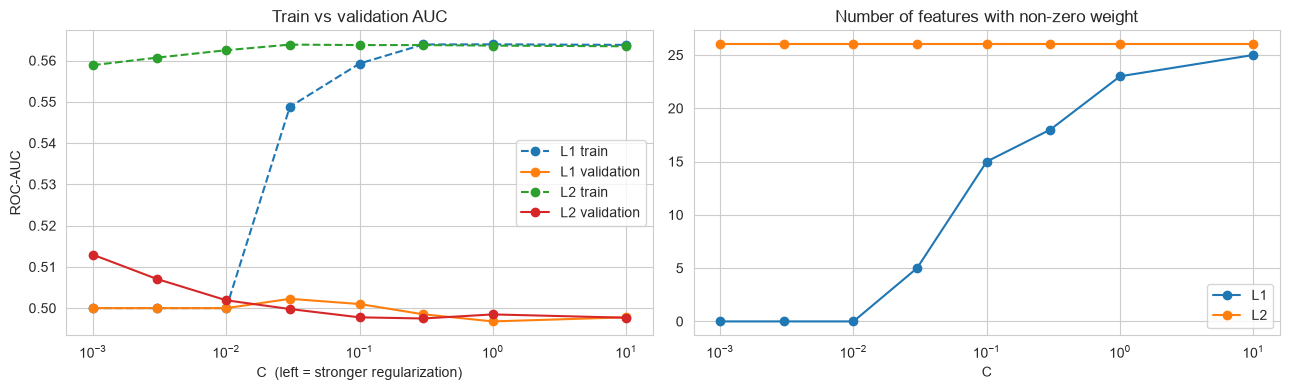

,penalty,C,train_auc,cv_auc,features_used
0,L1,0.0010,0.5000,0.5000,0
1,L1,0.0030,0.5000,0.5000,0
2,L1,0.0100,0.5000,0.5000,0
3,L1,0.0300,0.5488,0.5023,5
4,L1,0.1000,0.5593,0.5010,15
5,L1,0.3000,0.5639,0.4985,18
6,L1,1.0000,0.5639,0.4968,23
7,L1,10.0000,0.5638,0.4978,25
8,L2,0.0010,0.5589,0.5129,26
9,L2,0.0030,0.5607,0.5071,26


In [16]:
# ===== STEP 4: REGULARIZATION =====
tscv = TimeSeriesSplit(n_splits=5)    # time-ordered cross-validation (see Section 5)

# 4a. Logistic Regression: L1 vs L2 for different strengths C
rows = []
for name, l1_ratio in [("L1", 1), ("L2", 0)]:
    for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10]:
        model = make_pipeline(StandardScaler(),
                              LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=1000))
        cv_auc = cross_val_score(model, X_train, y_train, cv=tscv, scoring="roc_auc").mean()
        train_auc = roc_auc_score(y_train, model.fit(X_train, y_train).predict_proba(X_train)[:, 1])
        n_used = (model[-1].coef_ != 0).sum()
        rows.append([name, C, train_auc, cv_auc, n_used])

reg_results = pd.DataFrame(rows, columns=["penalty", "C", "train_auc", "cv_auc", "features_used"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, grp in reg_results.groupby("penalty"):
    ax[0].plot(grp["C"], grp["train_auc"], "--o", label=f"{name} train")
    ax[0].plot(grp["C"], grp["cv_auc"], "-o", label=f"{name} validation")
    ax[1].plot(grp["C"], grp["features_used"], "-o", label=name)
ax[0].set_xscale("log"); ax[0].set_xlabel("C  (left = stronger regularization)"); ax[0].set_ylabel("ROC-AUC")
ax[0].set_title("Train vs validation AUC"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_xlabel("C"); ax[1].set_title("Number of features with non-zero weight"); ax[1].legend()
plt.tight_layout()
plt.show()
reg_results

In [17]:
# 4b. Which features does L1 keep? (best C for L1 from the table above)
best_l1_C = reg_results[reg_results["penalty"] == "L1"].sort_values("cv_auc").iloc[-1]["C"]
lasso = make_pipeline(StandardScaler(),
                      LogisticRegression(C=best_l1_C, l1_ratio=1, solver="liblinear", max_iter=1000))
lasso.fit(X_train, y_train)
lasso_w = pd.Series(lasso[-1].coef_[0], index=FEATURES)
print(f"L1 with C={best_l1_C}: kept {(lasso_w != 0).sum()} of {len(FEATURES)} features")
print("Kept:", lasso_w[lasso_w != 0].sort_values().round(4).to_dict())
print("Removed (weight = 0):", list(lasso_w[lasso_w == 0].index))

L1 with C=0.03: kept 5 of 26 features
Kept: {'vix_change': -0.0275, 'close_vs_sma50': 0.0025, 'sp500_ret': 0.0075, 'stoch_k': 0.01, 'close_position': 0.0158}
Removed (weight = 0): ['ret_1', 'ret_5', 'ret_10', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_4', 'close_vs_sma200', 'rsi_14', 'macd_hist', 'bb_width', 'atr_pct', 'gap', 'intraday_ret', 'volume_ratio', 'obv_10', 'dist_52w_high', 'day_of_week', 'banknifty_ret', 'usdinr_ret', 'crude_ret']


In [18]:
# 4c. LightGBM without vs with regularization
lgbm_settings = {
    "No regularization": dict(n_estimators=500, learning_rate=0.1, max_depth=-1, num_leaves=127,
                              min_child_samples=2),
    "Regularized":       dict(n_estimators=200, learning_rate=0.03, max_depth=3, num_leaves=7,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, reg_lambda=5),
}
for name, params in lgbm_settings.items():
    model = LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=1, **params)
    cv_auc = cross_val_score(model, X_train, y_train, cv=tscv, scoring="roc_auc").mean()
    train_auc = roc_auc_score(y_train, model.fit(X_train, y_train).predict_proba(X_train)[:, 1])
    print(f"{name:18s} train AUC = {train_auc:.3f}   validation AUC = {cv_auc:.3f}   gap = {train_auc - cv_auc:.3f}")

No regularization  train AUC = 1.000   validation AUC = 0.517   gap = 0.483


Regularized        train AUC = 0.802   validation AUC = 0.520   gap = 0.283


### Regularization findings
- **L1:** for C ≤ 0.01 every weight becomes 0, so the model predicts a constant (AUC = 0.5, **underfitting**). At C = 0.03 it keeps only **5 features** (`vix_change`, `close_vs_sma50`, `sp500_ret`, `stoch_k`, `close_position`). As C grows, more features come back, training AUC rises to 0.564, but validation AUC *falls* to ~0.497. This is classic **overfitting**.
- **L2:** the best validation AUC (0.513) is at the **strongest** regularization (C = 0.001), and validation AUC falls as C grows while training AUC rises.
- **L1 vs L2:** L2 works better here. The signal is spread thinly across many features, and L1 throws away too much of it, while L2 keeps all features with small weights.
- **LightGBM:** without regularization it reaches **train AUC = 1.000** (it memorised the training days) but only 0.517 on validation. With regularization the train AUC drops to 0.802 and validation improves slightly to 0.520, so the **train-validation gap shrinks from 0.48 to 0.28**.
- **Main lesson:** on this data, **more regularization = better generalisation**. Most of the "patterns" in the training data are noise.

## 5. Hyperparameter Tuning

- **Parameters** are learned from data (e.g. logistic regression weights, tree split points).
- **Hyperparameters** are set by us *before* training (e.g. `C`, tree depth, learning rate). Wrong values cause overfitting or underfitting.

**GridSearchCV** tries every combination in a grid and keeps the one with the best validation score.

### Why TimeSeriesSplit and not normal K-fold?
Normal K-fold shuffles days, so the model would train on 2022 and be validated on 2019, i.e. it would **see the future**. That gives fake, inflated scores. `TimeSeriesSplit` always trains on the past and validates on the period right after it:

```
fold 1: [train]               [val]
fold 2: [train   train]             [val]
fold 3: [train   train   train]           [val]
...
```

### Why ROC-AUC as the score?
UP days are slightly more common, so accuracy can look good just by always saying UP. AUC measures how well the model **ranks** UP days above DOWN days, independent of the 0.5 threshold.

### What we tune and why
| Model | Hyperparameters | Effect |
|---|---|---|
| Logistic Regression | `C`, `l1_ratio` (L1/L2) | regularization strength and type |
| SVM (RBF kernel) | `C`, `gamma` | `C` = how much to punish mistakes, `gamma` = how wiggly the boundary is |
| Random Forest | `max_depth`, `min_samples_leaf` | size of each tree (overfitting control) |
| XGBoost | `n_estimators`, `max_depth`, `learning_rate`, `reg_lambda` | number/size of trees, step size, L2 penalty |
| LightGBM | `n_estimators`, `max_depth`, `learning_rate`, `min_child_samples` | number/size of trees, step size, minimum leaf size |

In [19]:
# ===== STEP 5: HYPERPARAMETER TUNING =====
search_space = {
    "Logistic Regression": (
        make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", max_iter=1000)),
        {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1],
         "logisticregression__l1_ratio": [0, 1]}),
    "SVM": (
        make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
        {"svc__C": [0.1, 1, 10],
         "svc__gamma": ["scale", 0.01, 0.001]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
        {"max_depth": [3, 5, 8],
         "min_samples_leaf": [20, 50, 100]}),
    "XGBoost": (
        XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1),
        {"n_estimators": [100, 300],
         "max_depth": [2, 3, 4],
         "learning_rate": [0.01, 0.05],
         "reg_lambda": [1, 10]}),
    "LightGBM": (
        LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=1),
        {"n_estimators": [100, 300],
         "max_depth": [2, 3, 4],
         "learning_rate": [0.01, 0.05],
         "min_child_samples": [20, 50]}),
}

best_models, searches, cv_scores = {}, {}, {}
for name, (model, grid) in search_space.items():
    search = GridSearchCV(model, grid, cv=tscv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    searches[name] = search
    cv_scores[name] = search.best_score_
    print(f"{name:20s} best validation AUC = {search.best_score_:.4f}   {search.best_params_}")

Logistic Regression  best validation AUC = 0.5129   {'logisticregression__C': 0.001, 'logisticregression__l1_ratio': 0}


SVM                  best validation AUC = 0.5295   {'svc__C': 10, 'svc__gamma': 'scale'}


Random Forest        best validation AUC = 0.5428   {'max_depth': 5, 'min_samples_leaf': 100}


XGBoost              best validation AUC = 0.5277   {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 300, 'reg_lambda': 10}


LightGBM             best validation AUC = 0.5275   {'learning_rate': 0.01, 'max_depth': 2, 'min_child_samples': 20, 'n_estimators': 300}


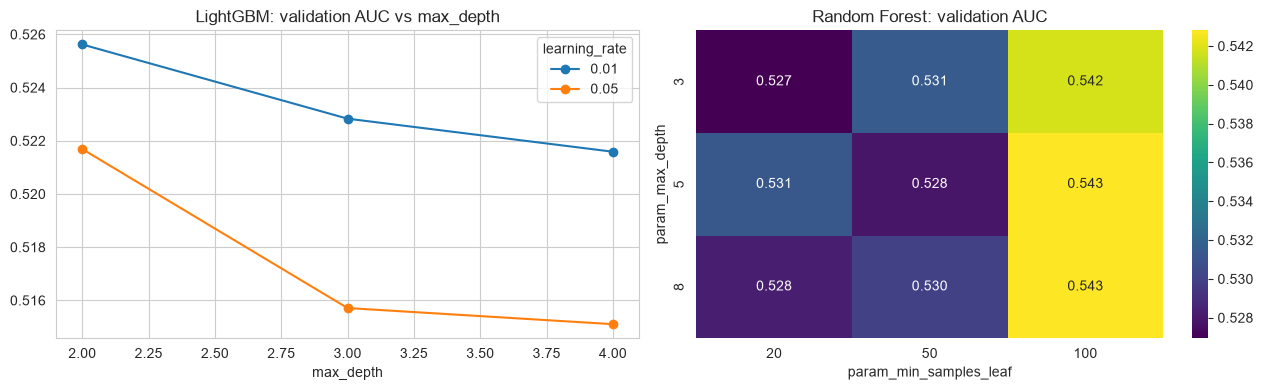

In [20]:
# 5b. How do hyperparameters change the score? (LightGBM and Random Forest)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

res = pd.DataFrame(searches["LightGBM"].cv_results_)
res.groupby(["param_max_depth", "param_learning_rate"])["mean_test_score"].mean().unstack().plot(marker="o", ax=ax[0])
ax[0].set_title("LightGBM: validation AUC vs max_depth"); ax[0].set_xlabel("max_depth"); ax[0].legend(title="learning_rate")

res = pd.DataFrame(searches["Random Forest"].cv_results_)
heat = res.pivot_table(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score")
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=ax[1])
ax[1].set_title("Random Forest: validation AUC")
plt.tight_layout()
plt.show()

### Tuning findings
| Model | Best settings | Validation AUC |
|---|---|---|
| Logistic Regression | C = 0.001, L2 | 0.513 |
| SVM | C = 10, gamma = scale | 0.530 |
| **Random Forest** | max_depth = 5, min_samples_leaf = 100 | **0.543** |
| XGBoost | 300 trees, depth 2, learning rate 0.01, reg_lambda 10 | 0.528 |
| LightGBM | 300 trees, depth 2, learning rate 0.01, min_child_samples 20 | 0.528 |

- Almost every model picked its **most conservative** settings: the shallowest trees (depth 2), the smallest learning rate (0.01) and the biggest leaves (100 days).
- **Random Forest heatmap:** `min_samples_leaf` matters more than `max_depth` (AUC goes from 0.527 to 0.543 when leaves must contain at least 100 days). Big leaves force each tree to learn only patterns that hold for many days.
- **LightGBM plot:** shallower trees and a slower learning rate always score better.
- This confirms the regularization result: with such a weak signal, **simpler models generalise better**.

## 6. Ensemble Techniques

An **ensemble** combines several models. Each model makes different mistakes, and when they are combined the mistakes partly cancel out, so predictions become **more stable**. This matters a lot for noisy market data, where any single model can be lucky or unlucky in a given period.

| Technique | How it works | What it fixes | In this project |
|---|---|---|---|
| **Bagging** | many deep-ish trees trained on random bootstrap samples, predictions averaged | **variance** (instability) | Random Forest (Section 5) |
| **Boosting** | small trees built one after another, each fixing the previous errors | **bias** (missed patterns) | XGBoost, LightGBM (Section 5) |
| **Soft Voting** | average the predicted probabilities of different model types | combines strengths | LR + RF + XGBoost + LightGBM |
| **Stacking** | a meta-model (Logistic Regression) learns how much to trust each base model | learns the best combination | same 4 base models |

We mix a **linear** model (LR) with **tree** models (RF, XGBoost, LightGBM) on purpose: they see the data in different ways, so their errors are less correlated.

In [21]:
# ===== STEP 6: ENSEMBLE TECHNIQUES =====
base_models = [
    ("lr",   best_models["Logistic Regression"]),
    ("rf",   best_models["Random Forest"]),
    ("xgb",  best_models["XGBoost"]),
    ("lgbm", best_models["LightGBM"]),
]

# Soft voting: average of the 4 probabilities
voting = VotingClassifier(estimators=base_models, voting="soft")

# Stacking: base models' probabilities -> Logistic Regression meta-model.
# The meta-model is trained on out-of-fold predictions (KFold without shuffling, inside the training data only).
stacking = StackingClassifier(estimators=base_models,
                              final_estimator=LogisticRegression(C=0.1, max_iter=1000),
                              cv=KFold(n_splits=5), stack_method="predict_proba")

for name, model in [("Voting Ensemble", voting), ("Stacking Ensemble", stacking)]:
    cv_scores[name] = cross_val_score(model, X_train, y_train, cv=tscv, scoring="roc_auc").mean()
    model.fit(X_train, y_train)
    best_models[name] = model
    print(f"{name:18s} validation AUC = {cv_scores[name]:.4f}")

if hasattr(stacking.final_estimator_, "coef_"):
    print("\nStacking meta-model weights (how much it trusts each model):",
          dict(zip([n for n, _ in base_models], stacking.final_estimator_.coef_[0].round(3))))

Voting Ensemble    validation AUC = 0.5293


Stacking Ensemble  validation AUC = 0.5300

Stacking meta-model weights (how much it trusts each model): {'lr': np.float64(0.012), 'rf': np.float64(0.232), 'xgb': np.float64(0.264), 'lgbm': np.float64(0.17)}


### Ensemble findings
- **Bagging (Random Forest) was the best model overall** (validation AUC 0.543). Averaging 300 different trees reduces **variance**, which is exactly what noisy data needs.
- **Boosting (XGBoost / LightGBM)** scored 0.528. Boosting mainly reduces **bias** by fitting the data harder. With very little real pattern to find, that strength is less useful, and it needs heavy regularization to avoid fitting noise.
- **Voting (0.529) and Stacking (0.530)** beat Logistic Regression, XGBoost and LightGBM alone, but not Random Forest. Averaging in the weaker Logistic Regression pulls the ensemble down a little.
- The **stacking meta-model learned to give Logistic Regression almost zero weight** (0.01) and to trust the tree models (0.17-0.26). This shows stacking doing its job: learning which models are useful.
- Ensembles are mainly about **stability**: they are rarely the single best on one test, but they are less likely to be the worst.

## 7. Performance Analysis

All models are now tested on the **unseen last 20%** of days.

| Metric | Meaning for us |
|---|---|
| Accuracy | % of days where the direction was right |
| Precision (UP) | when the model says UP, how often is it really UP? (matters if we buy on UP signals) |
| Recall (UP) | of all real UP days, how many did the model catch? |
| F1 | balance of precision and recall |
| ROC-AUC | ranking quality, independent of threshold (0.5 = random) |
| Train - test gap | big gap = overfitting |

**Choosing the final model:** we pick it by **validation AUC on the training period** (Sections 5-6), *not* by test results. Picking by test score would be cheating, because the test set must stay "unseen".

In [22]:
# ===== STEP 7: PERFORMANCE ANALYSIS =====
# 7a. Comparison table on the test set
rows = [{"Model": "Baseline: always UP", "Accuracy": accuracy_score(y_test, np.ones(len(y_test))),
         "Precision": precision_score(y_test, np.ones(len(y_test))), "Recall": 1.0,
         "F1": f1_score(y_test, np.ones(len(y_test))), "ROC-AUC": 0.5}]
test_proba = {}
for name, model in best_models.items():
    p = model.predict_proba(X_test)[:, 1]
    pred = (p > 0.5).astype(int)
    test_proba[name] = p
    train_acc = accuracy_score(y_train, model.predict(X_train))
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "Train acc": train_acc,
                 "Train-test gap": train_acc - accuracy_score(y_test, pred),
                 "Validation AUC": cv_scores[name]})
results = pd.DataFrame(rows).set_index("Model")

final_name = max(cv_scores, key=cv_scores.get)     # best VALIDATION score, not test score
final_model = best_models[final_name]
print("Final model (chosen by validation AUC):", final_name)
results.round(4)

Final model (chosen by validation AUC): Random Forest


,Accuracy,Precision,Recall,F1,ROC-AUC,Train acc,Train-test gap,Validation AUC
Model,,,,,,,,
Baseline: always UP,0.4831,0.4831,1.0000,0.6515,0.5000,NaN,NaN,NaN
Logistic Regression,0.4944,0.4838,0.6965,0.5710,0.5035,0.5550,0.0606,0.5129
SVM,0.4831,0.4830,0.9961,0.6506,0.5389,0.8600,0.3769,0.5295
Random Forest,0.5169,0.5000,0.8288,0.6237,0.5199,0.6104,0.0935,0.5428
XGBoost,0.4906,0.4834,0.7938,0.6009,0.5134,0.6151,0.1245,0.5277
LightGBM,0.4887,0.4818,0.7743,0.5940,0.5235,0.6212,0.1325,0.5275
Voting Ensemble,0.4868,0.4810,0.7860,0.5968,0.5160,0.6128,0.1259,0.5293
Stacking Ensemble,0.4831,0.4831,1.0000,0.6515,0.5203,0.5522,0.0691,0.5300


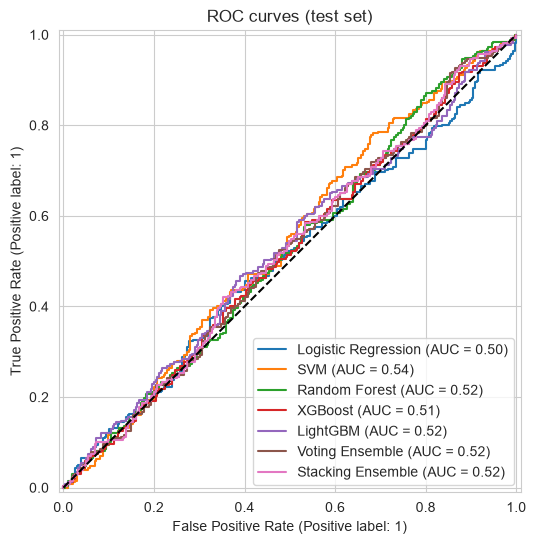

In [23]:
# 7b. ROC curves of all models on the test set
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="random guess")
ax.set_title("ROC curves (test set)")
plt.show()

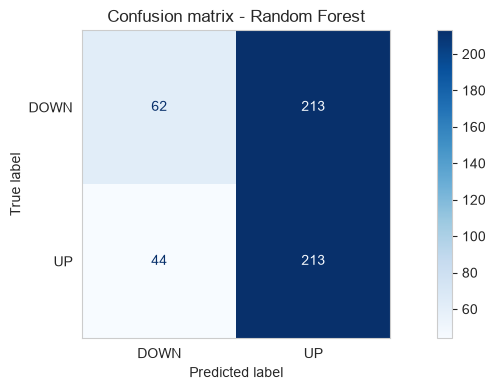

In [24]:
# 7c. Confusion matrix of the final model
ConfusionMatrixDisplay.from_predictions(y_test, (test_proba[final_name] > 0.5).astype(int),
                                        display_labels=["DOWN", "UP"], cmap="Blues")
plt.title(f"Confusion matrix - {final_name}")
plt.grid(False)
plt.show()

### 7d. Confidence: is the model more accurate when it is more sure?
In real life a trader does not need to act every day. If the model is only right 53% of the time overall but **more often right on days when it is confident**, that is useful: act on confident days, ignore the rest.

We look at days where the probability is far from 0.5 (e.g. above 0.55 or below 0.45).

In [25]:
# 7d. Accuracy when the model is confident
p = test_proba[final_name]
rows = []
for margin in [0.0, 0.02, 0.04, 0.05, 0.06, 0.08]:
    sure = np.abs(p - 0.5) >= margin                 # days where the model is at least this sure
    if sure.sum() > 0:
        rows.append({"only act if |p - 0.5| >=": margin,
                     "days acted on": sure.sum(),
                     "% of days": sure.mean() * 100,
                     "accuracy on those days": accuracy_score(y_test[sure], (p[sure] > 0.5).astype(int))})
confidence_table = pd.DataFrame(rows)
confidence_table.round(3)

,only act if |p - 0.5| >=,days acted on,% of days,accuracy on those days
0,0.0000,532,100.0000,0.5170
1,0.0200,374,70.3010,0.5030
2,0.0400,239,44.9250,0.4940
3,0.0500,179,33.6470,0.4750
4,0.0600,142,26.6920,0.4860
5,0.0800,80,15.0380,0.5000


### 7e. Backtest: would this have made money?
Accuracy alone does not tell us if a strategy is profitable. We simulate a simple, realistic **long-only** strategy for an investor during the test period:

- probability > **0.55** -> **BUY / stay invested** in NIFTY
- probability < **0.45** -> **EXIT** to cash
- in between -> **no new trade**, keep the current position
- the investor starts invested (like a normal investor)
- every buy or sell costs **0.05%** (brokerage, taxes, slippage)

The thresholds 0.55 / 0.45 were fixed **before** looking at test results.

We compare with **buy-and-hold** (just buy NIFTY and keep it) using:
- **Total return / CAGR**: how much money was made (CAGR = per year)
- **Sharpe ratio**: return per unit of risk (higher is better, > 1 is good)
- **Max drawdown**: the worst fall from a peak (smaller is better; this is what scares real investors)

,Total return %,CAGR %,Sharpe,Max drawdown %,% days invested
Buy & Hold,-8.3200,-4.0300,-0.2500,-15.7700,100.0000
Logistic Regression,-10.3800,-5.0600,-0.3800,-17.1100,95.6800
LightGBM,-8.3300,-4.0400,-0.2700,-15.1500,92.4800
Random Forest,-6.5300,-3.1500,-0.1800,-15.7700,99.2500


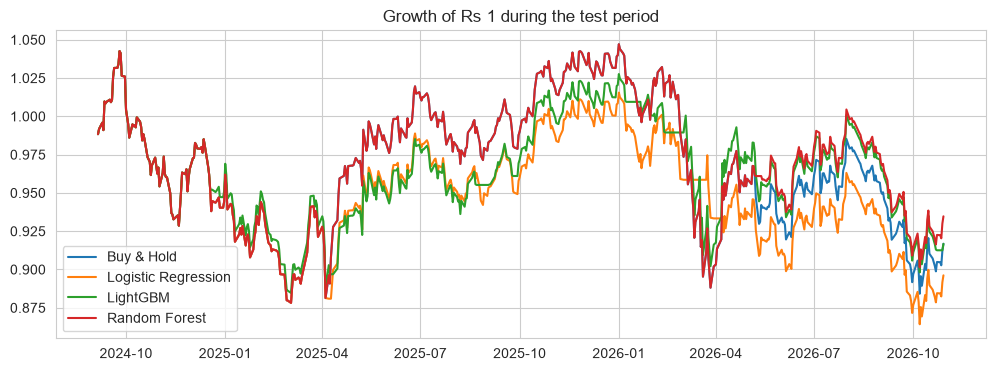

In [26]:
# 7e. Backtest
COST = 0.0005      # 0.05% per buy or sell

def signals_to_position(p, buy=0.55, sell=0.45):
    signal = pd.Series(np.nan, index=test.index)
    signal[p > buy] = 1          # BUY / stay invested
    signal[p < sell] = 0         # EXIT to cash
    return signal.ffill().fillna(1)    # no signal -> keep previous position (start invested)

def performance(daily_ret):
    equity = (1 + daily_ret).cumprod()
    years = len(daily_ret) / 252
    return {"Total return %": (equity.iloc[-1] - 1) * 100,
            "CAGR %": (equity.iloc[-1] ** (1 / years) - 1) * 100,
            "Sharpe": daily_ret.mean() / daily_ret.std() * np.sqrt(252),
            "Max drawdown %": (equity / equity.cummax() - 1).min() * 100}

strategy_returns = {"Buy & Hold": test["next_ret"]}
time_in_market = {"Buy & Hold": 100.0}
for name in ["Logistic Regression", "LightGBM", final_name]:
    position = signals_to_position(test_proba[name])
    trades = position.diff().abs().fillna(0)
    strategy_returns[name] = position * test["next_ret"] - trades * COST
    time_in_market[name] = position.mean() * 100

backtest = pd.DataFrame({name: performance(r) for name, r in strategy_returns.items()}).T
backtest["% days invested"] = pd.Series(time_in_market)
display(backtest.round(2))

for name, r in strategy_returns.items():
    plt.plot((1 + r).cumprod(), label=name)
plt.title("Growth of Rs 1 during the test period")
plt.legend()
plt.show()

### 7f. Which features matter? (SHAP)
**SHAP** values explain each prediction by showing how much each feature pushed the probability up or down. We use it on the tuned LightGBM model.

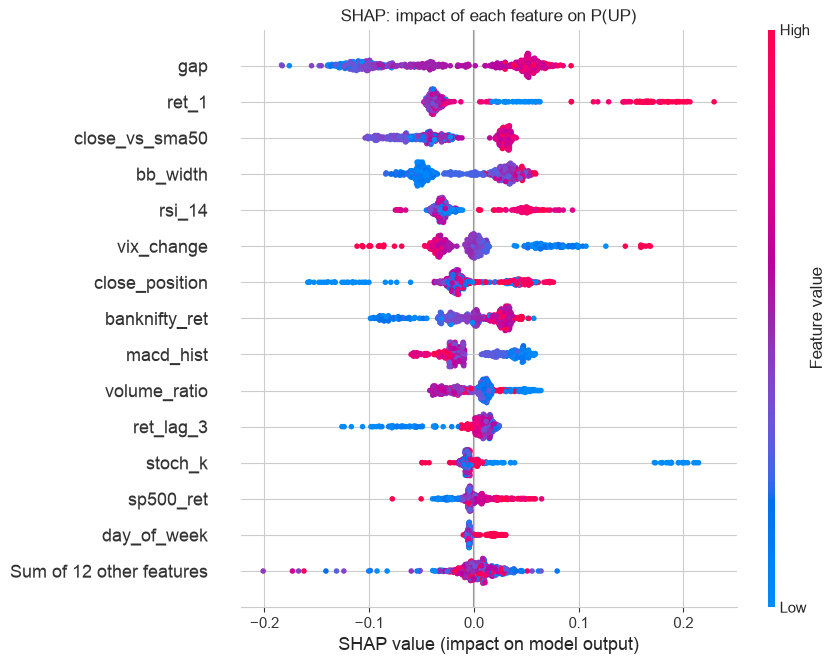

In [27]:
# 7f. SHAP feature importance (LightGBM)
explainer = shap.TreeExplainer(best_models["LightGBM"])
shap_values = explainer(X_test)
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP: impact of each feature on P(UP)")
plt.show()

### Performance findings
- **Final model = Random Forest** (best validation AUC). On the unseen test period it reached **51.7% accuracy and AUC 0.520**. That beats "always UP" (48.3%) but not clearly "same as today" (52.4%).
- **Overfitting check:** SVM scored 86% on training data but 48% on test, a huge gap even after tuning. Random Forest's gap is 9 points, Logistic Regression's 6.
- SVM had the highest test AUC (0.539), but we did **not** switch to it. Choosing a model by its test score would turn the test set into a second validation set and make our reported result dishonest. SVM also predicted UP on 99.6% of days.
- **Confusion matrix:** Random Forest says UP on ~80% of days. It catches most real UP days (recall 83%), but only half of its UP calls are right (precision 50%). The model learned an UP bias from the 2016-2024 bull market (55.2% UP days), while the test period had only 48.3% UP days. This is a **regime change**.
- **Confidence:** in this test period, higher confidence did **not** give higher accuracy (47.5% on the 34% most confident days). The model's confidence was not reliable here.
- **Backtest:** buy-and-hold lost 8.3%; the Random Forest strategy lost 6.5% (Sharpe -0.18 vs -0.25) with the same max drawdown. The model's probabilities rarely fell below 0.45, so it stayed invested on 99% of days. The small difference is likely luck.
- **SHAP:** the most influential features are `gap`, `ret_1`, `close_vs_sma50`, `bb_width`, `rsi_14` and `vix_change`. The patterns make financial sense:
  - a strong up-day today (`ret_1`) raises P(UP): short-term momentum
  - price above its 50-day average raises P(UP): trend
  - rising VIX lowers P(UP): fear
  - a very low stochastic gives a strong UP push: oversold bounce

  The model learned **real, known market effects**. They are just very weak.

## 8. Real-life use

### 8a. Walk-forward retraining
Markets change over time (new regimes, new volatility levels). In real life we would **retrain the model regularly** on all data seen so far. Here we retrain the final model every **63 trading days (~3 months)** during the test period and predict the next 3 months each time. This is the most honest simulation of how the model would be used live.

In [28]:
# ===== STEP 8: REAL-LIFE USE =====
# 8a. Walk-forward: retrain every 63 days on all past data, predict the next 63 days
X_all, y_all = data[FEATURES], data["target"]

def walk_forward(model, first_row, step=63):
    proba = []
    for start in range(first_row, len(data), step):
        end = min(start + step, len(data))
        m = clone(model).fit(X_all.iloc[:start], y_all.iloc[:start])   # train only on the past
        proba.extend(m.predict_proba(X_all.iloc[start:end])[:, 1])     # predict the next 3 months
    return np.array(proba)

wf_proba = walk_forward(final_model, split)

print(f"Static model       : accuracy = {accuracy_score(y_test, test_proba[final_name] > 0.5):.4f}   "
      f"AUC = {roc_auc_score(y_test, test_proba[final_name]):.4f}")
print(f"Walk-forward model : accuracy = {accuracy_score(y_test, wf_proba > 0.5):.4f}   "
      f"AUC = {roc_auc_score(y_test, wf_proba):.4f}")

position = signals_to_position(wf_proba)
wf_returns = position * test["next_ret"] - position.diff().abs().fillna(0) * COST
display(pd.DataFrame({"Buy & Hold": performance(test["next_ret"]),
                      f"{final_name} (walk-forward)": performance(wf_returns)}).T.round(2))

Static model       : accuracy = 0.5169   AUC = 0.5199
Walk-forward model : accuracy = 0.5226   AUC = 0.5248


,Total return %,CAGR %,Sharpe,Max drawdown %
Buy & Hold,-8.3200,-4.0300,-0.2500,-15.7700
Random Forest (walk-forward),-9.8900,-4.8100,-0.3200,-17.8800


### 8b. Robustness check: 7 years instead of 2
Our test set has only ~530 days, and it was mostly a falling market. With so few days, an accuracy difference of ±2% can be pure luck (standard error ≈ 2.2%). To see the bigger picture we run the same walk-forward process from **2019 to 2026** (~1,900 days, including the 2020 COVID crash and the 2021 and 2023 rallies) and compare with the two baselines **year by year**.

Note: the hyperparameters were tuned on 2016-2024 data, so 2019-2024 is slightly optimistic. Only the 2024-2026 part is fully unseen.

In [29]:
# 8b. Walk-forward from 2019, compared with baselines year by year
first_2019 = data.index.searchsorted(pd.Timestamp("2019-01-01"))
long = data.iloc[first_2019:].copy()
long["p_up"] = walk_forward(final_model, first_2019)

long["Model"] = (long["p_up"] > 0.5).astype(int) == long["target"]
long["Always UP"] = long["target"] == 1
long["Same as today"] = (long["ret_1"] > 0).astype(int) == long["target"]

by_year = long.groupby(long.index.year)[["Model", "Always UP", "Same as today"]].mean() * 100
by_year.loc["All (2019-2026)"] = long[["Model", "Always UP", "Same as today"]].mean() * 100
print(f"Walk-forward AUC 2019-2026: {roc_auc_score(long['target'], long['p_up']):.4f}")
print("Accuracy (%) by year:")
by_year.round(1)

Walk-forward AUC 2019-2026: 0.5355
Accuracy (%) by year:


,Model,Always UP,Same as today
Date,,,
2019,53.9000,53.1000,53.1000
2020,57.2000,58.8000,54.4000
2021,54.8000,55.6000,57.3000
2022,50.8000,50.0000,58.9000
2023,58.8000,57.6000,55.9000
2024,53.3000,54.9000,51.2000
2025,50.6000,50.2000,57.4000
2026,51.2000,47.8000,46.8000
All (2019-2026),53.9000,53.6000,54.6000


### 8c. Tomorrow's signal
Finally, the model is trained on **all** available data and used on the most recent day to give the signal for the next trading day. To get a fresh signal: delete the `data/` folder and run the notebook again after 3:30 PM IST.

> This is a student project, not investment advice.

In [30]:
# 8c. Train on all data and predict the next trading day
live_model = clone(final_model).fit(X_all, y_all)
p_up = live_model.predict_proba(latest_day[FEATURES])[:, 1][0]

if p_up > 0.55:
    signal = "BUY / stay invested"
elif p_up < 0.45:
    signal = "EXIT / stay in cash"
else:
    signal = "NO TRADE (model not confident, keep current position)"

print("Last data date    :", latest_day.index[0].date(), f"(NIFTY close = {latest_day['Close'].iloc[0]:,.2f})")
print("Model             :", final_name)
print(f"P(UP next day)    : {p_up:.3f}")
print("Signal            :", signal)

Last data date    : 2026-10-30 (NIFTY close = 23,053.10)
Model             : Random Forest
P(UP next day)    : 0.507
Signal            : NO TRADE (model not confident, keep current position)


## 9. Conclusion
### What we built
A complete and **honest** pipeline for predicting NIFTY 50's next-day direction:
- EDA
- 31 derived features (including global markets)
- 5 tuned classifiers
- bagging, boosting, voting and stacking ensembles
- a realistic backtest with costs
- walk-forward retraining
- SHAP explanations

**No data leakage:** we used only information known at 3:30 PM, lagged foreign markets by one day, split by time, and used time-series cross-validation.

### What the results say
| | Accuracy | AUC |
|---|---|---|
| Random Forest, unseen test (Sep 2024 - Oct 2026) | 51.7% | 0.520 |
| Random Forest, 7-year walk-forward (2019 - 2026) | 53.9% | 0.536 |
| Baseline "always UP" (2019 - 2026) | 53.6% | 0.500 |
| Baseline "same as today" (2019 - 2026) | 54.6% | - |

- The accuracy is at the lower end of our expected range (52-58%).
- **The models did not clearly beat the simple baselines**, and the backtest was close to buy-and-hold.

### Why
1. **The market is close to efficient.** RSI, moving averages and similar indicators are public and used by thousands of professional traders, so any easy pattern gets traded away. EDA already showed that daily returns have almost zero autocorrelation.
2. **Regime change.** The models learned from a mostly rising market (2016-2024) and were tested on a falling one (2024-2026).
3. **Low signal-to-noise.** Every feature's correlation with tomorrow's return was below 0.07. This is also why regularization and conservative hyperparameters always won.

### Real-life meaning
- This model should **not** be used alone to trade NIFTY daily. That is an honest, useful result in itself: many online projects claim 70-90% accuracy, and such claims almost always come from data leakage (shuffled splits, or using information from after the prediction time). Our pipeline shows what remains once leakage is removed.
- What the project *does* show investors:
  - which signals matter (momentum, trend, VIX change)
  - that volatility is far more predictable than direction
  - how to test any trading idea properly before risking money

### Future improvements
1. **Data that is not in the price:** FII/DII flows, options data (put-call ratio, open interest), news and social-media sentiment, earnings announcements.
2. **Predict volatility instead of direction:** EDA showed volatility clustering is strong, and volatility forecasts are directly useful for risk management and position sizing.
3. **Longer horizon** (e.g. 5-day or weekly direction), where trend signals are less drowned by daily noise.
4. **Pre-open model** using GIFT Nifty and overnight US moves, to predict the open-to-close move of the next day.